In [1]:
import os
import numpy as np
import random
import matplotlib.pyplot as plt
import pandas as pd

from glob import glob
from tqdm import tqdm
from PIL import Image
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import Dataset
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks
from torchvision import tv_tensors
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchvision.transforms import v2
from torchvision.transforms.v2 import functional as TVF
from torchvision import models
import torch.nn.functional as F

import lightning as L
from lightning.pytorch.callbacks import ModelCheckpoint, LearningRateMonitor
from lightning.pytorch.loggers import CSVLogger

from skimage import io
from sklearn.model_selection import train_test_split
from sklearn.metrics import pairwise_distances, classification_report, confusion_matrix

# 3 OpenSet classification model

## Model architecture definition

For a resolving of the Open-Set classification task in the scope of our research we utilized an Class Anchor Clustering approach [1], where as an encoder has been utilized a well-known CNN ResNet18[2] with embedding vector size of 512 and a Fully-Connected layer as classsification layer.

***References:*** 

[1] D. Miller, N. Suenderhauf, M. Milford, and F. Dayoub, ‘Class Anchor Clustering: A Loss for Distance-Based Open Set Recognition’, in Proceedings of the IEEE/CVF Winter Conference on Applications of Computer Vision, pp. 3570–3578.

[2] He, K., Zhang, X., Ren, S., Sun, J., 2016. Deep residual learning for image recognition, in: Proceedings of the IEEE conference on computer vision and pattern recognition, pp. 770–778.

In [2]:
from common.configuration import DatasetPath, ModelPath, species_native, species_invasive, species_label_map_all, species_classes_map_all
from common.osc_classification import OpenSetClassificationModel, get_static_transforms, get_model_transforms, distance_to_scores, scores_to_class

## Dataset

In [3]:
OBJECTS_ROOT = DatasetPath.reference_images

In [4]:
from common.img_utils import pad2size, scale2factor


class PollenClassificationDataset(Dataset):
    def __init__(self, dataset,
                 classes_map,
                 known_classes,
                 static_transform=None,
                 random_transform=None):
        self.classes_map = classes_map
        self.transform = random_transform
        self.known_classes = known_classes
        self._all_samples = []
        self.class_to_index_remap = {}
        for i, c in enumerate(self.known_classes):
            self.class_to_index_remap[classes_map[c]] = i
        self.index_to_class_remap = {v: k for k,
                                     v in self.class_to_index_remap.items()}

        total_samples = 0
        for idx, sample in enumerate(tqdm(dataset)):
            img = Image.open(sample["image"])
            img.load()
            if sample["label"] in classes_map:
                c_number = classes_map[sample["label"]]
            else:
                c_number = -1
                raise ValueError(f"Unknown class name: {sample['label']}")
            if static_transform is not None:
                img = static_transform(img)
            self._all_samples.append((c_number, img))
            total_samples += 1
        print(f"Total samples: {total_samples}")

    def __len__(self):
        return len(self._all_samples)

    def __getitem__(self, idx):
        if idx >= len(self._all_samples):
            raise IndexError("Index out of range")
        c_number, image = self._all_samples[idx]
        label = self.class_to_index_remap[c_number]

        if self.transform:
            image = self.transform(image)

        image = torch.as_tensor(image) if not isinstance(
            image, torch.Tensor) else image
        label = torch.as_tensor(label) if not isinstance(
            label, torch.Tensor) else label

        return image, label.long(), c_number

In [5]:
species_label_map_all

{0: 'Acer',
 1: 'Alnus',
 2: 'Apiaceae',
 3: 'Artemisia',
 4: 'Betula',
 5: 'Chenopodiaceae',
 6: 'Corylus',
 7: 'Picea',
 8: 'Pinus',
 9: 'Plantago',
 10: 'Poaceae',
 11: 'Populus tremula',
 12: 'Quercus',
 13: 'Rumex',
 14: 'Salix',
 15: 'Tilia',
 16: 'Urtica',
 17: 'Ulmus',
 18: 'Ambrosia',
 19: 'Taraxacum',
 20: 'Malus',
 -1: 'Unknown'}

In [6]:
def save_test_subset(test_dataset: list):
    tst_labels = []
    tst_images = []
    for test_sample in test_dataset:
        tst_labels.append(test_sample["label"])
        tst_images.append(test_sample["image"])
    test_df = pd.DataFrame.from_dict(
        {"label": tst_labels, "image": tst_images})
    os.makedirs("Save", exist_ok=True)
    test_df.to_csv("Save/classification_test_set.csv")


def load_dataset(data_dir: str, train_classes: list, pseudo_unknown_classes: list, classes_map: dict) -> tuple:
    trainval_dataset = []
    test_dataset = []
    for c in tqdm(train_classes):
        if not os.path.isdir(os.path.join(data_dir, c)):
            continue
        images = glob(os.path.join(data_dir, c, "*.png"))
        names = [os.path.split(n)[1].rsplit("_", maxsplit=1)[0]
                 for n in images]
        names.sort()
        names = list(set(names))
        trainval_pictures, test_pictures = train_test_split(
            names, test_size=0.15, random_state=42)

        for pic in trainval_pictures:
            trainval_img = glob(os.path.join(data_dir, c, f"{pic}_*.png"))
            trainval_dataset.extend(
                [{"label": c, "image": im} for im in trainval_img])

        for pic in test_pictures:
            test_img = glob(os.path.join(data_dir, c, f"{pic}_*.png"))
            test_dataset.extend([{"label": c, "image": im} for im in test_img])

    #Add all pseudo_unknown_classes into test subset
    for c in tqdm(pseudo_unknown_classes):
        if not os.path.isdir(os.path.join(data_dir, c)):
            continue

        images = glob(os.path.join(data_dir, c, "*.png"))
        names = [os.path.split(n)[1].rsplit("_", maxsplit=1)[0]
                 for n in images]
        names.sort()
        names = list(set(names))
        # Sample 15% of images for test purposes.
        # The rest will be used for indexing and callibration
        _, test_inv_pictures = train_test_split(
            names, test_size=0.15, random_state=42)

        for pic in test_inv_pictures:
            test_img = glob(os.path.join(data_dir, c, f"{pic}_*.png"))
            test_dataset.extend([{"label": c, "image": im} for im in test_img])

    save_test_subset(test_dataset)

    print(f"Known train classes: {train_classes}")
    print(f"Pseudo unknown classes (for test): {pseudo_unknown_classes}")

    train_dataset, val_dataset = train_test_split(
        trainval_dataset, test_size=0.176, random_state=42) # 15% from 85%
    print(f"Train dataset size: {len(train_dataset)}")
    print(f"Validation dataset size: {len(val_dataset)}")
    print(f"Test dataset size: {len(test_dataset)}")

    static_transforms = get_static_transforms()
    train_dinamic_transforms = v2.Compose([
        v2.RandomHorizontalFlip(p=0.5),
        v2.RandomVerticalFlip(p=0.5),
        v2.RandomAffine(degrees=180, translate=(0.1, 0.1)),
        v2.ColorJitter(brightness=.5, hue=.1),
        v2.RandomAutocontrast(),
        get_model_transforms(),
    ])
    val_dinamic_transforms = v2.Compose([
        get_model_transforms(),
    ])

    print("\nLoad Train Dataset")
    dataset_train = PollenClassificationDataset(
        train_dataset,
        classes_map,
        train_classes,
        static_transform=static_transforms,
        random_transform=train_dinamic_transforms)
    print("\nLoad Validation Dataset")
    dataset_val = PollenClassificationDataset(
        val_dataset,
        classes_map,
        train_classes,
        static_transform=static_transforms,
        random_transform=val_dinamic_transforms)
    print("\nLoad Test Dataset")
    dataset_test = PollenClassificationDataset(
        test_dataset,
        classes_map,
        train_classes + pseudo_unknown_classes,
        static_transform=static_transforms,
        random_transform=val_dinamic_transforms)
    return dataset_train, dataset_val, dataset_test


dataset_train, dataset_val, dataset_test = load_dataset(
    OBJECTS_ROOT, species_native, species_invasive, species_classes_map_all)

100%|██████████| 2/2 [00:00<00:00, 181.82it/s]


Known train classes: ['Acer', 'Alnus', 'Apiaceae', 'Artemisia', 'Betula', 'Chenopodiaceae', 'Corylus', 'Picea', 'Pinus', 'Plantago', 'Poaceae', 'Populus tremula', 'Quercus', 'Rumex', 'Salix', 'Tilia', 'Urtica', 'Ulmus', 'Ambrosia']
Pseudo unknown classes (for test): ['Taraxacum', 'Malus']
Train dataset size: 5948
Validation dataset size: 1271
Test dataset size: 1430

Load Train Dataset


100%|██████████| 5948/5948 [00:09<00:00, 616.40it/s]


Total samples: 5948

Load Validation Dataset


100%|██████████| 1271/1271 [00:02<00:00, 593.88it/s]


Total samples: 1271

Load Test Dataset


100%|██████████| 1430/1430 [00:02<00:00, 538.01it/s]

Total samples: 1430


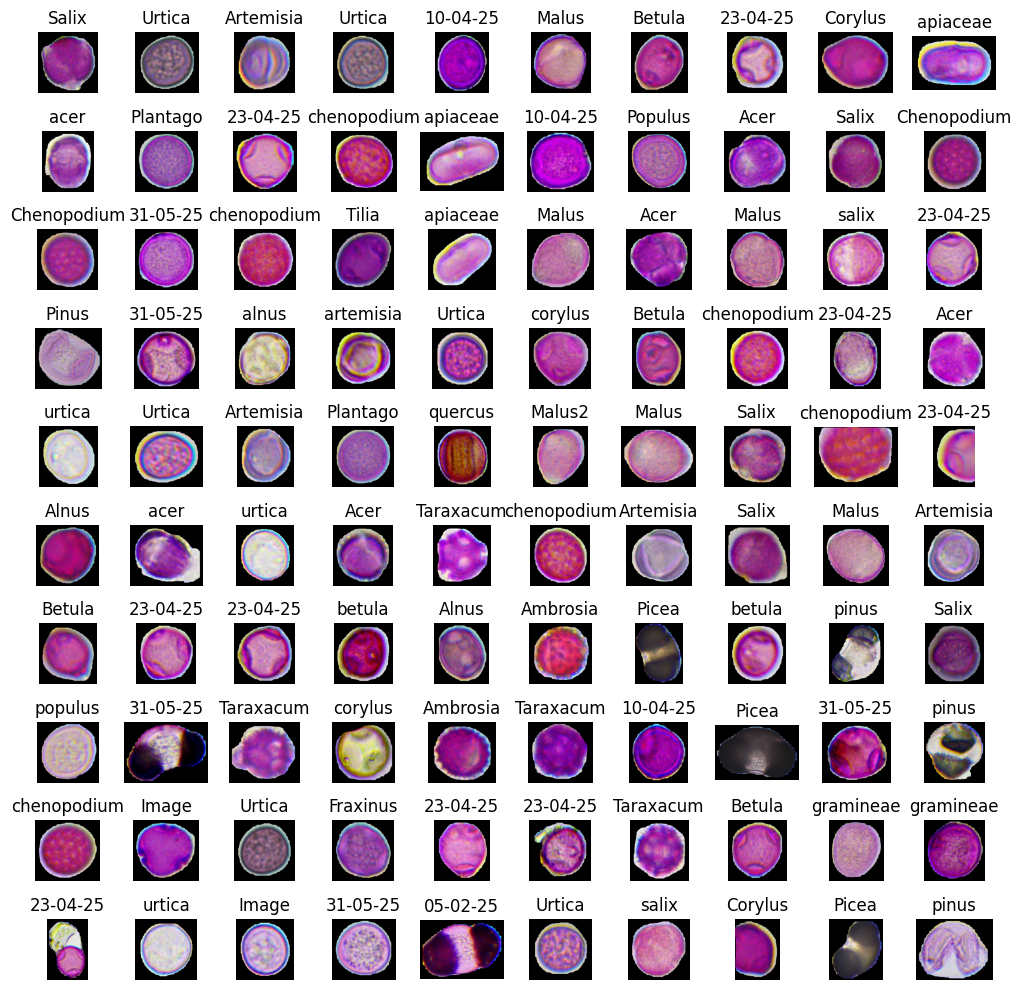

In [7]:
all_obj_images = glob(os.path.join(OBJECTS_ROOT,  "**", "*.png"), recursive=True)
all_obj_images = random.sample(all_obj_images, 100)
fig, axs = plt.subplots(nrows=10, ncols=10, figsize=(10, 10))
for ax, img_path in zip(axs.flatten(), all_obj_images):
    image_rgb = io.imread(img_path)
    ax.set_title(os.path.basename(img_path).split(" ")[0].split("_")[0])
    ax.imshow(image_rgb)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## Utils

In [8]:
def plot(imgs, row_title=None, labels=None, **imshow_kwargs):
    if labels != None:
        ax_title = True
    else:
        ax_title = False
    if not isinstance(imgs[0], list):
        # Make a 2d grid even if there's just 1 row
        imgs = [imgs]

    num_rows = len(imgs)
    num_cols = len(imgs[0])
    _, axs = plt.subplots(nrows=num_rows, ncols=num_cols, squeeze=False)
    for row_idx, row in enumerate(imgs):
        for col_idx, img in enumerate(row):
            boxes = None
            masks = None
            if isinstance(img, tuple):
                img, target = img
                if isinstance(target, dict):
                    boxes = target.get("boxes")
                    masks = target.get("masks")
                elif isinstance(target, tv_tensors.BoundingBoxes):
                    boxes = target
                else:
                    raise ValueError(f"Unexpected target type: {type(target)}")
            img = TVF.to_image(img)
            if img.dtype.is_floating_point and img.min() < 0:
                # Poor man's re-normalization for the colors to be OK-ish. This
                # is useful for images coming out of Normalize()
                img -= img.min()
                img /= img.max()

            img = TVF.to_dtype(img, torch.uint8, scale=True)
            black_pixels = (img != 0).all(dim=0)
            img[:, ~black_pixels] = 255
            if boxes is not None:
                img = draw_bounding_boxes(img, boxes, colors="yellow", width=3)
            if masks is not None:
                img = draw_segmentation_masks(img, masks.to(torch.bool), colors=["green"] * masks.shape[0], alpha=.65)

            ax = axs[row_idx, col_idx]
            ax.imshow(img.permute(1, 2, 0).numpy(), **imshow_kwargs)
            ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])
            if ax_title:
                ax.set_title(labels[col_idx])

    if row_title is not None:
        for row_idx in range(num_rows):
            axs[row_idx, 0].set(ylabel=row_title[row_idx])

    plt.tight_layout()

## Neural Network Training 

In [9]:
train_loader = torch.utils.data.DataLoader(
    dataset_train,
    batch_size=64,
    shuffle=True,
    num_workers=0 if os.name == 'nt' else 6
)
val_loader = torch.utils.data.DataLoader(
    dataset_val,
    batch_size=32,
    shuffle=False,
    num_workers=0 if os.name == 'nt' else 6
)
test_loader = torch.utils.data.DataLoader(
    dataset_test,
    batch_size=6,
    shuffle=False,
    num_workers=0 if os.name == 'nt' else 6
)

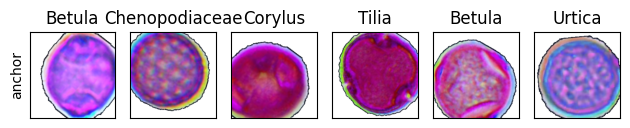

In [10]:
for image, label, c_number in train_loader:
    plot(image[:6], row_title=["anchor"], labels=[species_label_map_all[l.item()] for l in label[:6]])
    break

## Training of the model

Import the model definition from the common module.

Next, define CACLoss

In [11]:
class CACLoss(nn.Module):
    def __init__(self, num_known_classes, lbda=0.1):
        super().__init__()
        self.num_known_classes = num_known_classes
        self.lbda = lbda

    def forward(self, distances, gt):
        '''Returns CAC loss, as well as the Anchor and Tuplet loss components separately for visualisation.'''
        true = torch.gather(distances, 1, gt.view(-1, 1)).view(-1)
        non_gt = torch.Tensor([[i for i in range(self.num_known_classes) if gt[x] != i] for x in range(len(distances))]).long().cuda()
        others = torch.gather(distances, 1, non_gt)
    	
        anchor = torch.mean(true)
    
        tuplet = torch.exp(-others+true.unsqueeze(1))
        tuplet = torch.mean(torch.log(1+torch.sum(tuplet, dim = 1)))
    
        total = self.lbda*anchor + tuplet
    
        return total, anchor, tuplet

To simplification of the tarining process, we used a pytorch lightning, thus, define a wrapper for the model.

In [12]:
class PollenOSCEmbeddingsModule(L.LightningModule):
    def __init__(self,
                 n_classes,
                 alpha=10,  # Magnitude of the anchor point
                 optim_lr=0.001,
                 optim_betas=(0.9, 0.999),
                 optim_eps=1e-08,
                 optim_weight_decay=0.01,
                 check_val=20,
                 freeze_epochs=10):
        super().__init__()
        # call this to save (arguments) to the checkpoint
        self.save_hyperparameters()
        self.lr = optim_lr

        self.cac_loss = CACLoss(n_classes)

        self.best_score = 1
        self.best_val_epoch = -1

        self.model = OpenSetClassificationModel(n_classes=n_classes)

        # initialising with anchors
        anchors = torch.diag(torch.Tensor([alpha for i in range(n_classes)]))
        self.model.set_anchors(anchors)

        self.train_step_outputs = []
        self.val_step_outputs = []
        self.test_step_outputs = []
        self.train_losses = []
        self.val_losses = []
        self.test_losses = []

        # self.freeze_backbone()

    def freeze_backbone(self):
        for param in self.model.model.parameters():
            param.requires_grad = False

    def unfreeze_all(self):
        for param in self.model.parameters():
            param.requires_grad = True

    def on_train_epoch_start(self):
        pass
        # if self.current_epoch == self.hparams.freeze_epochs:
        #     self.unfreeze_all()

    def forward(self, inputs):
        return self.model(inputs)

    def _shared_eval_step(self, batch, batch_idx):
        anchor, label, c_number = batch
        l_anchor = len(anchor)
        outputs = self.model(anchor)
        loss, anchorLoss, tupletLoss = self.cac_loss(outputs[1], label)
        return loss, anchorLoss, tupletLoss, l_anchor

    def training_step(self, batch, batch_idx):
        loss, anchorLoss, tupletLoss, l_anchor_out = self._shared_eval_step(
            batch, batch_idx)
        pred = {"train_loss": loss,
                "anchorLoss": anchorLoss,
                "tupletLoss": tupletLoss,
                "train_number": l_anchor_out}
        self.train_step_outputs.append(pred)
        return loss

    def on_train_epoch_end(self):
        outputs = self.train_step_outputs
        train_loss, train_anchor_loss, train_tuplet_loss, num_items = 0, 0, 0, 0
        for output in outputs:
            train_loss += output["train_loss"].sum().item()
            train_anchor_loss += output["anchorLoss"].sum().item()
            train_tuplet_loss += output["tupletLoss"].sum().item()
            num_items += output["train_number"]

        mean_train_loss = torch.tensor(train_loss / num_items)
        self.log("train_loss", mean_train_loss)
        self.log("train_anchor_loss", train_anchor_loss / num_items)
        self.log("train_tuplet_loss", train_tuplet_loss / num_items)
        self.train_losses.append(mean_train_loss.item())
        self.train_step_outputs.clear()  # free memory

    def validation_step(self, batch, batch_idx):
        loss, anchorLoss, tupletLoss, l_anchor_out = self._shared_eval_step(
            batch, batch_idx)
        pred = {"val_loss": loss,
                "anchorLoss": anchorLoss,
                "tupletLoss": tupletLoss,
                "val_number": l_anchor_out}
        self.val_step_outputs.append(pred)

    def on_validation_epoch_end(self):
        outputs = self.val_step_outputs
        val_loss, val_anchor_loss, val_tuplet_loss, num_items = 0, 0, 0, 0
        for output in outputs:
            val_loss += output["val_loss"].sum().item()
            val_anchor_loss += output["anchorLoss"].sum().item()
            val_tuplet_loss += output["tupletLoss"].sum().item()
            num_items += output["val_number"]

        mean_val_loss = torch.tensor(val_loss / num_items)
        self.val_losses.append(mean_val_loss.item())
        self.val_step_outputs.clear()  # free memory

        self.log("val_loss", mean_val_loss)
        self.log("val_anchor_loss", val_anchor_loss / num_items)
        self.log("val_tuplet_loss", val_tuplet_loss / num_items)

        if mean_val_loss < self.best_score:
            self.best_score = mean_val_loss
            self.best_val_epoch = self.current_epoch

    def test_step(self, batch, batch_idx):
        anchor, label, c_number = batch
        anchor_emb, anchor_out = self.model(anchor)
        celoss = self.celoss(anchor_out, label)
        loss = celoss
        l_anchor_out = len(anchor_out)

        true_pred = 0
        for i, l in enumerate(label):
            if torch.argmax(l).item() == torch.argmax(anchor_out).item():
                true_pred += 1
        acc = true_pred / l_anchor_out
        pred = {"test_loss": loss, "test_number": l_anchor_out, "test_acc": acc}
        self.test_step_outputs.append(pred)

    def on_test_epoch_end(self):
        outputs = self.test_step_outputs
        test_loss, num_items, test_acc = 0, 0, 0
        for output in outputs:
            test_loss += output["test_loss"].sum().item()
            num_items += output["test_number"]
            test_acc += output["test_acc"]
        mean_test_loss = torch.tensor(test_loss / num_items)
        mean_test_acc = torch.tensor(test_acc / len(outputs))
        print('mean_test_loss', mean_test_loss)
        print('mean_test_acc', mean_test_acc)
        self.test_losses.append(mean_test_loss.item())
        self.log('mean_test_loss', mean_test_loss)
        self.log('mean_test_acc', mean_test_acc)
        self.test_step_outputs.clear()

    def configure_optimizers(self):

        self.optimizer = torch.optim.AdamW(
            self.model.model.parameters(),
            lr=self.lr,
            weight_decay=self.hparams.optim_weight_decay
        )
        return {
            "optimizer": self.optimizer,
            "lr_scheduler": {
                "scheduler": ReduceLROnPlateau(self.optimizer, factor=0.3, patience=5),
                "frequency": self.hparams.check_val,
                "monitor": "val_loss",
                "interval": "epoch",
            }
        }

    def plot_losses(self):
        plt.figure(figsize=(10, 5))
        plt.plot([i for i in range(len(self.train_losses))],
                 self.train_losses, label='Train Loss')
        plt.plot([i * self.hparams.check_val for i in range(len(self.val_losses))],
                 self.val_losses, label='Validation Loss')
        plt.xlabel('Iterations')
        plt.ylabel('Loss')
        plt.title('Training and Validation Losses')
        plt.legend()
        plt.show()

Create and prepare for training an instance of the Model.

In [13]:
model = PollenOSCEmbeddingsModule(n_classes=len(species_native), check_val=1, freeze_epochs=30) # Do not train backbone
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Use device: {device}")
model = model.to(device)

Use device: cuda


Define callbacks for the training process

In [14]:
checkpoint_callback = ModelCheckpoint(
    filename='checkpoint-AdamW-{epoch:02d}-{val_loss:.2f}',
    # auto_insert_metric_name=False,
    dirpath="./history",
    monitor='val_loss',
    mode='min')
lr_logger = LearningRateMonitor()
logger = CSVLogger("logs", name="osc_cac_loss")

### Learning rate optimization

To optimize learning rate we utilized an appoach implemented in Pytorch Lightning library which is based on idea proposed by L. Smith [1]

[1] L. N. Smith, ‘Cyclical Learning Rates for Training Neural Networks’, in 2017 IEEE Winter Conference on Applications of Computer Vision (WACV), 2017, pp. 464–472.

In [15]:
torch.set_float32_matmul_precision('medium')

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
i:\git\Pollen-Analyzer\.venv\Lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
`weights_only` was not set, defaulting to `False`.
i:\git\Pollen-Analyzer\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


Finding best initial lr:   0%|          | 0/100 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_steps=100` reached.
Restoring states from the checkpoint path at i:\git\Pollen-Analyzer\.lr_find_c9cf568a-2c53-42e1-a866-76c2d41b18ea.ckpt
Restored all states from the checkpoint at i:\git\Pollen-Analyzer\.lr_find_c9cf568a-2c53-42e1-a866-76c2d41b18ea.ckpt
Learning rate set to 6.918309709189363e-05
C:\Users\Александр\AppData\Local\Temp\ipykernel_18452\1573588837.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


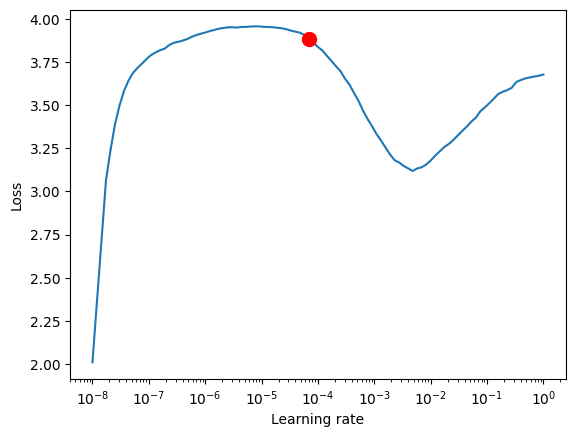

In [16]:
trainer = L.Trainer(logger=logger,
                    log_every_n_steps=2,  # Increase, if epoch size is large
                    callbacks=[checkpoint_callback, lr_logger],
                    precision="16-mixed",
                    check_val_every_n_epoch=model.hparams.check_val,
                    max_epochs=100,
                    # accumulate_grad_batches=2,
                    )

tuner = L.pytorch.tuner.Tuner(trainer)
lf_finder = tuner.lr_find(model,
                          train_dataloaders=train_loader)
fig = lf_finder.plot(suggest=True)
fig.show()

Print the suggested learning rate and apply LR suggestion to the model..

In [17]:
print(f"Suggested LR: {lf_finder.suggestion()}")
model.lr = lf_finder.suggestion()
model.hparams.optim_lr = lf_finder.suggestion()

Suggested LR: 6.918309709189363e-05


### Training loop and results

Start a training process of the model.

In [18]:
trainer.fit(model, 
            train_dataloaders=train_loader, 
            val_dataloaders=val_loader,     
)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
i:\git\Pollen-Analyzer\.venv\Lib\site-packages\lightning\pytorch\utilities\model_summary\model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.

  | Name     | Type                       | Params | Mode  | FLOPs
------------------------------------------------------------------------
0 | cac_loss | CACLoss                    | 0      | train | 0    
1 | model    | OpenSetClassificationModel | 11.2 M | train | 0    
------------------------------------------------------------------------
11.2 M    Trainable params
361       Non-trainable params
11.2 M    Total params
44.746    Total estimated model params size (MB)
70        Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

i:\git\Pollen-Analyzer\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


Plot curves of loss changes during training

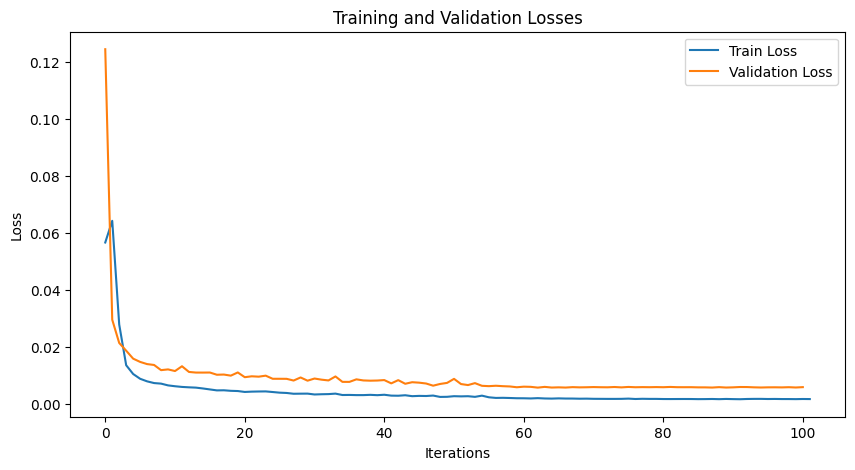

In [19]:
model.plot_losses()

## OSC NN Model Predictions Visualization

In [20]:
def prepare_data(embeddings_lists: list, labels_lists: list):
    all_labels_sorted = []
    all_embeddings_sorted = []
    class_boundaries = [0]
    for i, embeddings_list in enumerate(embeddings_lists):
        labels_list = labels_lists[i]
        class_to_idx = {}
        for i, class_name in enumerate(np.unique(labels_list)):
            class_to_idx[class_name] = i
        all_labels_idx = [class_to_idx[label] for label in labels_list]
        sorted_indices = sorted(range(len(embeddings_list)), key=lambda i: all_labels_idx[i])
        start = len(all_labels_sorted) + 1
        all_embeddings_sorted.extend([embeddings_list[i] for i in sorted_indices])
        all_labels_sorted.extend([labels_list[i] for i in sorted_indices])
    
        for i in range(start, len(all_labels_sorted)):
            if all_labels_sorted[i] != all_labels_sorted[i-1]:
                class_boundaries.append(i)
        class_boundaries.append(len(all_labels_sorted))

    return all_labels_sorted, all_embeddings_sorted, class_boundaries

In [21]:
def add_class_markings(ax, class_boundaries, labels):
    tick_locs = [(class_boundaries[i] + class_boundaries[i+1] - 1) / 2 for i in range(len(class_boundaries)-1)]
    ax.set_xticks(tick_locs)
    ax.set_yticks(tick_locs)
    ax.set_xticklabels([labels[int(loc)] for loc in tick_locs])
    ax.set_yticklabels([labels[int(loc)] for loc in tick_locs])
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    for boundary in class_boundaries[1:-1]:
        ax.axhline(y=boundary-1, color='k', linestyle='-', linewidth=1)
        ax.axvline(x=boundary-1, color='k', linestyle='-', linewidth=1)

In [22]:
def plot_matrix(embeddings_lists: list, labels_lists: list, subtitle: str=None, axes_class_markings: bool=True):
    all_labels_sorted, all_embeddings_sorted, class_boundaries = prepare_data(embeddings_lists, labels_lists)

    pairwise_dist = pairwise_distances(all_embeddings_sorted, metric="euclidean")#cosine
    fig, ax = plt.subplots(figsize=(10, 10))
    im = ax.imshow(pairwise_dist, cmap='Blues_r')#, norm=PowerNorm(gamma=0.5, vmin=0, vmax=1)
    plt.colorbar(im, fraction=0.046, pad=0.04)

    if axes_class_markings:
        add_class_markings(ax, class_boundaries, all_labels_sorted)

    if subtitle != None:
        plt.title('Pairwise Distance Matrix\n' + subtitle)
    else:
        plt.title('Pairwise Distance Matrix')
    plt.tight_layout()
    plt.show()
    del all_labels_sorted
    del all_embeddings_sorted
    del class_boundaries

In [23]:
model_class_to_c_number_remap = {}
for i, c in enumerate(species_native):
    model_class_to_c_number_remap[i] = species_classes_map_all[c]

def prediction_to_class_name(prediction):
    predicted_c_number = model_class_to_c_number_remap.get(prediction, -1)
    return species_label_map_all[predicted_c_number]

def process_loader(model, loader):
    all_embeddings = []
    all_predictions = []
    all_labels = []
    with torch.no_grad():
        for batch in loader:
            imgs, labels, c_number = batch
            labels_str = [species_label_map_all[l.item()] for l in c_number]
            
            imgs = imgs.cuda()
            embeddings, pred_distances = model(imgs)
            scores = distance_to_scores(pred_distances)
            prediction = scores_to_class(scores, 8.0)
            predict_str = [prediction_to_class_name(l.item()) for l in prediction.cpu()]
            
            all_embeddings.append(embeddings.cpu())
            all_labels.extend(labels_str)
            all_predictions.extend(predict_str)
        all_embeddings = torch.cat(all_embeddings, dim=0).cpu().numpy()
        
    return all_embeddings, all_labels, all_predictions

In [24]:
loaders_list = [test_loader, val_loader, train_loader] #test_loader, val_loader, train_loader
embeddings_data = []
labels_data_str = []
labels_predictions = []

### Feature space analysis

To analyze feature space we projected it into 2-dimentional space using T-SNE method.

## Save pure OSC model as Pytorch

In [25]:
model = PollenOSCEmbeddingsModule.load_from_checkpoint(checkpoint_callback.best_model_path)
model.eval()
torch.save(model.model.state_dict(), ModelPath.osc_classification)

## Evaluate performance

### Test samples from test subset

In [26]:
from collections import Counter
from sklearn.metrics import f1_score, precision_score, recall_score

In [27]:
def plot_confusion_matrix(y_true, y_pred, subtitle: str = ""):
    fig, ax = plt.subplots(figsize=(8,8))
    labels = sorted(set(y_true + y_pred))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    if len(subtitle) > 0:
        plt.title("Confusion Matrix\n" + subtitle)
    else:
        plt.title("Confusion Matrix")
    plt.ylabel("Class")
    plt.tight_layout()
    plt.show()

In [28]:
def loader_to_cf(loader, title):
    print("-" * 10, title, "-" * 10)
    embeddings, labels, preds = process_loader(model.cuda(), loader)
    embeddings_data.append(embeddings)
    labels_data_str.append(labels)
    labels_predictions.append(preds)
    plot_matrix([embeddings], [labels], 'CAC Loss')
    plot_confusion_matrix(labels, preds)
    print(classification_report(labels, preds))

---------- Train ----------


i:\git\Pollen-Analyzer\common\osc_classification.py:94: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4419.)
  scores[range(scores.shape[0]), candidate.T] < threshold, candidate, -1)


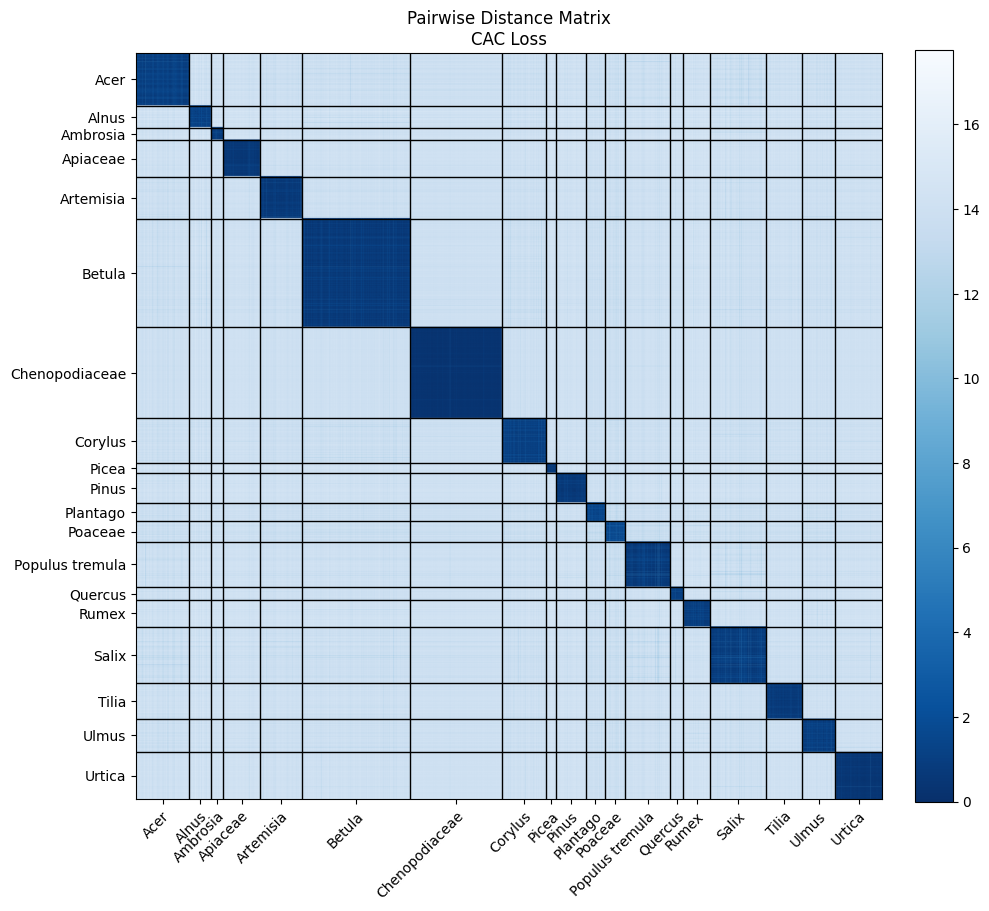

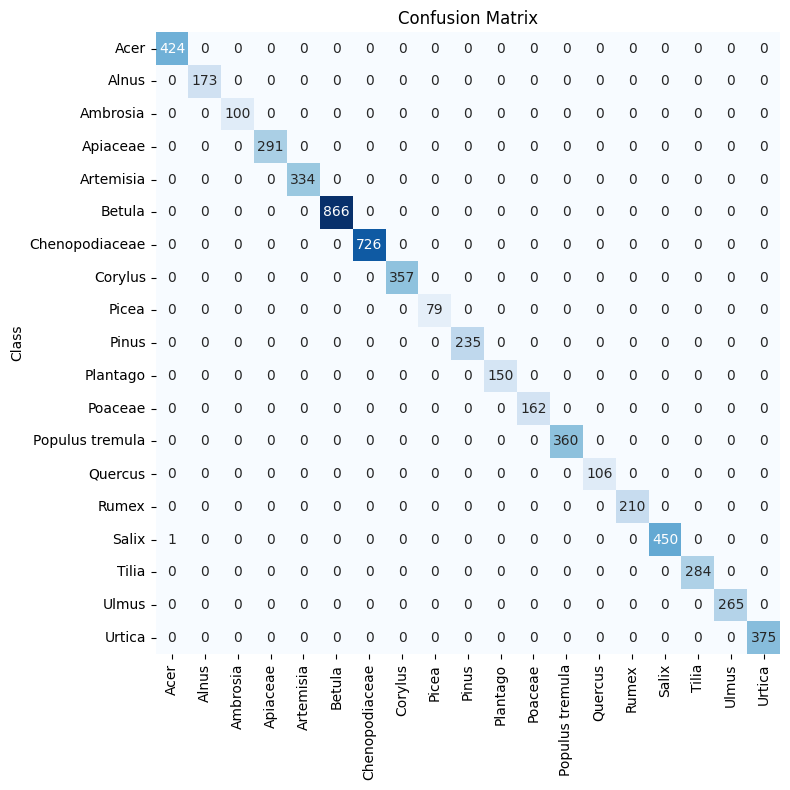

                 precision    recall  f1-score   support

           Acer       1.00      1.00      1.00       424
          Alnus       1.00      1.00      1.00       173
       Ambrosia       1.00      1.00      1.00       100
       Apiaceae       1.00      1.00      1.00       291
      Artemisia       1.00      1.00      1.00       334
         Betula       1.00      1.00      1.00       866
 Chenopodiaceae       1.00      1.00      1.00       726
        Corylus       1.00      1.00      1.00       357
          Picea       1.00      1.00      1.00        79
          Pinus       1.00      1.00      1.00       235
       Plantago       1.00      1.00      1.00       150
        Poaceae       1.00      1.00      1.00       162
Populus tremula       1.00      1.00      1.00       360
        Quercus       1.00      1.00      1.00       106
          Rumex       1.00      1.00      1.00       210
          Salix       1.00      1.00      1.00       451
          Tilia       1.00    

In [29]:
loader_to_cf(loaders_list[2], "Train")

---------- Validation ----------


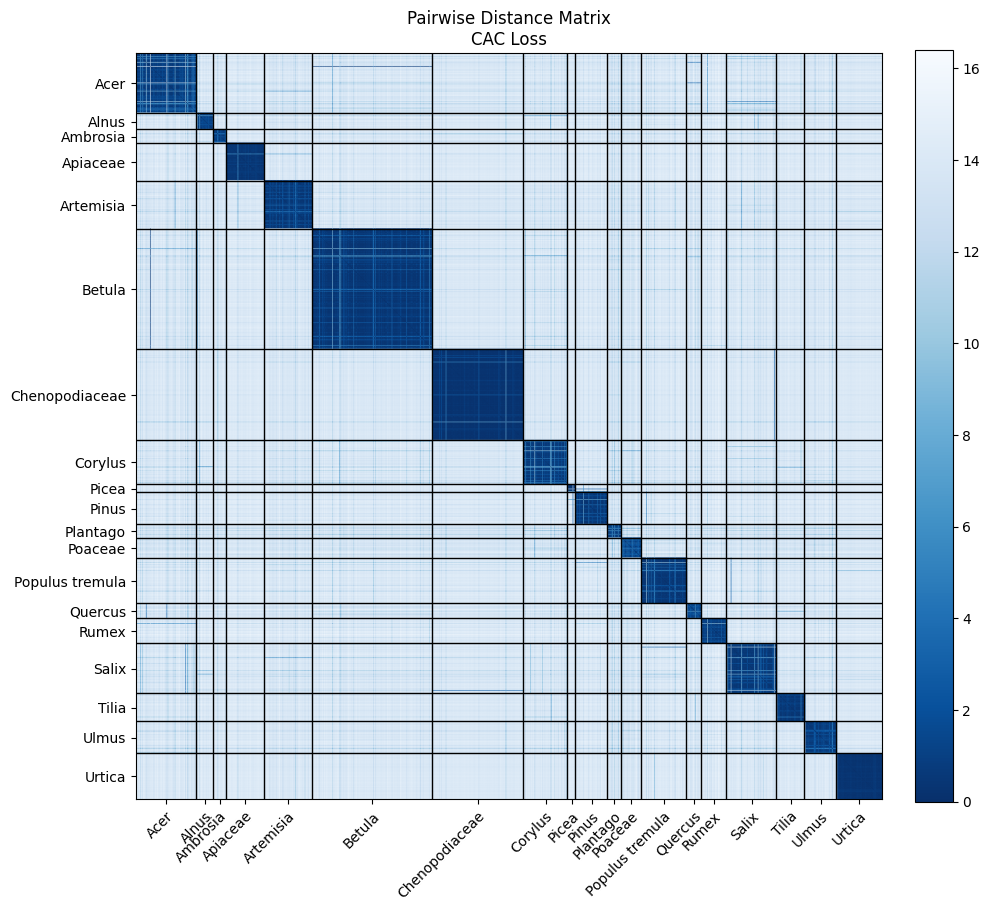

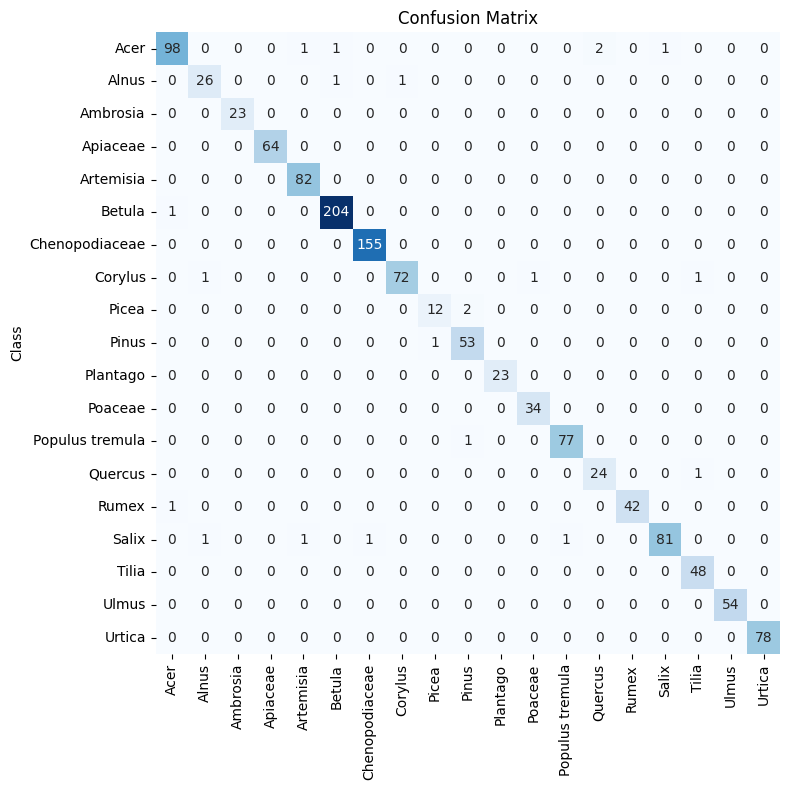

                 precision    recall  f1-score   support

           Acer       0.98      0.95      0.97       103
          Alnus       0.93      0.93      0.93        28
       Ambrosia       1.00      1.00      1.00        23
       Apiaceae       1.00      1.00      1.00        64
      Artemisia       0.98      1.00      0.99        82
         Betula       0.99      1.00      0.99       205
 Chenopodiaceae       0.99      1.00      1.00       155
        Corylus       0.99      0.96      0.97        75
          Picea       0.92      0.86      0.89        14
          Pinus       0.95      0.98      0.96        54
       Plantago       1.00      1.00      1.00        23
        Poaceae       0.97      1.00      0.99        34
Populus tremula       0.99      0.99      0.99        78
        Quercus       0.92      0.96      0.94        25
          Rumex       1.00      0.98      0.99        43
          Salix       0.99      0.95      0.97        85
          Tilia       0.96    

In [30]:
loader_to_cf(loaders_list[1], "Validation")